**Problem 1a**

In [180]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

url = 'https://raw.githubusercontent.com/iperezv-cpu/ML/refs/heads/main/Housing.csv'
# Load housing dataset
housing = pd.read_csv(url)

# Display first five rows
housing.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


**Normalizing with 0's and 1's**

In [181]:
# List of variables to map

varlist =  ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']

# Defining the map function
def binary_map(x):
    return x.map({'yes': 1, 'no': 0})

# Applying the function to the housing list
housing[varlist] = housing[varlist].apply(binary_map)
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


In [182]:
housing['furnishingstatus'] = housing['furnishingstatus'].map({
    'unfurnished': 0,
    'semi-furnished': 1,
    'furnished': 2
})
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2


**using all Features**

In [183]:
X3 = housing[
    ['area',
     'bedrooms',
     'bathrooms',
     'stories',
     'mainroad',
     'guestroom',
     'basement',
     'hotwaterheating',
     'airconditioning',
     'parking',
     'prefarea',
     'furnishingstatus'

     ]
].values

Y = housing['price'].values

print(X3.shape)
print(Y.shape)

(545, 12)
(545,)


**Validation and splitting**

In [184]:
# 80/20 Training and Testing Split
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, Y, train_size=0.8, test_size=0.2, random_state=42
)

# Take 20% of training data for validation
X3_train, X3_val, y3_train, y3_val = train_test_split(
    X3_train, y3_train, test_size=0.2, random_state=42
)

print("Training samples:", len(X3_train))
print("Validation samples:", len(X3_val))
print("Testing samples:", len(X3_test))

Training samples: 348
Validation samples: 88
Testing samples: 109


**Standardization**

In [185]:
# Standardize X using training data only
scaler = StandardScaler()

X3_train_scaled = scaler.fit_transform(X3_train)
X3_val_scaled = scaler.transform(X3_val)
X3_test_scaled = scaler.transform(X3_test)

# Convert X data to PyTorch tensors
X3_train_t = torch.tensor(X3_train_scaled,
                          dtype=torch.float32)

X3_val_t = torch.tensor(X3_val_scaled,
                        dtype=torch.float32)

X3_test_t = torch.tensor(X3_test_scaled,
                         dtype=torch.float32)

# Scale prices to improve gradient descent
price_scale = y3_train.mean()

y3_train_t = torch.tensor(y3_train / price_scale,
                          dtype=torch.float32)

y3_val_t = torch.tensor(y3_val / price_scale,
                        dtype=torch.float32)

print(X3_train_t.shape)
print(X3_val_t.shape)
print(X3_test_t.shape)

torch.Size([348, 12])
torch.Size([88, 12])
torch.Size([109, 12])


**Model**

In [186]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Linear(X3_train.shape[1], 32),
    nn.ReLU(),
    nn.Linear(32, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

**Training**

In [187]:
def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val,
                  t_c_train, t_c_val):

    train_losses = []
    val_losses = []

    for epoch in range(1, n_epochs + 1):

        model.train()
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

        # Save losses for plotting
        train_losses.append(loss_train.item())
        val_losses.append(loss_val.item())

        if epoch == 1 or epoch % 1000 == 0:
            print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
                  f" Validation loss {loss_val.item():.4f}")

    return train_losses, val_losses

In [188]:
from torch import optim

optimizer = optim.SGD(model.parameters(), lr=1e-3)

train_losses, val_losses = training_loop(
    n_epochs = 5000,
    optimizer = optimizer,
    model = model,
    loss_fn = nn.MSELoss(),
    t_u_train = X3_train_t,
    t_u_val = X3_val_t,
    t_c_train = y3_train_t.reshape(-1, 1),
    t_c_val = y3_val_t.reshape(-1, 1)
)
# Find best epoch based on validation loss

best_epoch = np.argmin(val_losses) + 1
best_loss = np.min(val_losses)

print("Best Epoch:", best_epoch)
print("Lowest Validation Loss:", best_loss)


Epoch 1, Training loss 1.0478, Validation loss 1.1504
Epoch 1000, Training loss 0.0985, Validation loss 0.0933
Epoch 2000, Training loss 0.0712, Validation loss 0.0707
Epoch 3000, Training loss 0.0600, Validation loss 0.0630
Epoch 4000, Training loss 0.0542, Validation loss 0.0596
Epoch 5000, Training loss 0.0506, Validation loss 0.0579
Best Epoch: 5000
Lowest Validation Loss: 0.057862404733896255


**Plot training and validation losses**

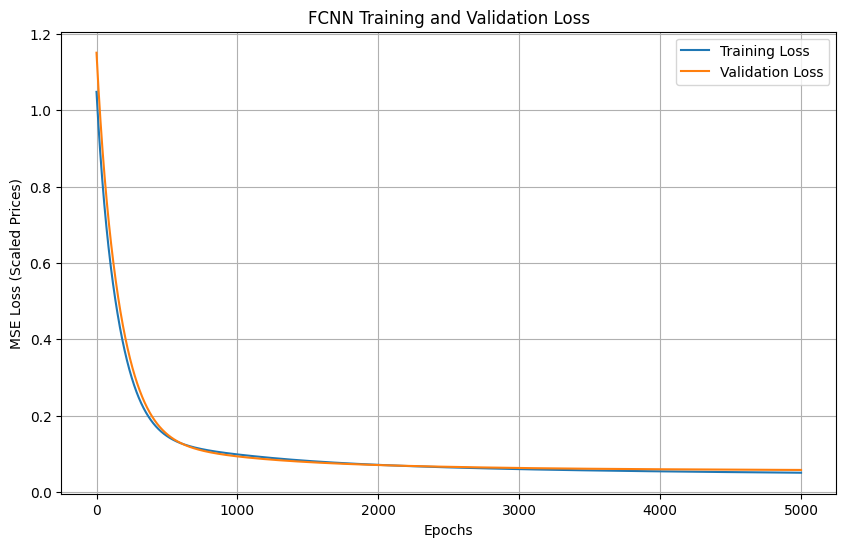

In [189]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss (Scaled Prices)')
plt.title('FCNN Training and Validation Loss')

plt.legend()
plt.grid(True)
plt.show()

In [190]:
# Check validation performance
model.eval()

with torch.no_grad():
    val_pred = model(X3_val_t).numpy().flatten() * price_scale

val_r2 = r2_score(y3_val, val_pred)

print("Validation R²:", val_r2)
print("Final Training Loss:", train_losses[-1])
print("Final Validation Loss:", val_losses[-1])

print("Predicted Prices:", val_pred[:5])
print("Actual Prices:", y3_val[:5])

Validation R²: 0.5924748071409982
Final Training Loss: 0.05057923123240471
Final Validation Loss: 0.057862404733896255
Predicted Prices: [4937340.25086046 3542087.40857279 3252022.15609398 3935139.44001945
 5600091.71856306]
Actual Prices: [3990000 2660000 3780000 3465000 5873000]


**Calculate MSE, RMSE, AND R^2**

In [191]:
from sklearn.metrics import mean_squared_error, r2_score

# Test neural network
model.eval()

with torch.no_grad():
    y3_pred_t = model(X3_test_t)

# Convert predictions back to original housing prices
y3_pred = y3_pred_t.numpy().flatten() * price_scale

# Performance metrics
mse = mean_squared_error(y3_test, y3_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y3_test, y3_pred)

print("FCNN Performance")
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

FCNN Performance
MSE: 2229694357623.1675
RMSE: 1493216.1121629942
R²: 0.5588755821073061


**Problem 1b**

In [192]:
# SVR Kernel Comparison Using Scaled Data
from sklearn.svm import SVR
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

kernels = ['linear', 'poly', 'rbf']

r2_scores = []
mse_scores = []
rmse_scores = []

for kernel in kernels:

    svr_model = SVR(
        kernel=kernel,
        C=1e3
    )

    # Train using scaled X and scaled y
    svr_model.fit(X3_train_scaled, y3_train / price_scale)

    # Predict using scaled X validation data
    y_pred_scaled = svr_model.predict(X3_val_scaled)

    # Convert predictions back to original house-price units
    y_pred = y_pred_scaled * price_scale

    # Evaluate against original validation prices
    r2_scores.append(r2_score(y3_val, y_pred))

    mse_scores.append(mean_squared_error(y3_val, y_pred))

    rmse_scores.append(
        np.sqrt(mean_squared_error(y3_val, y_pred))
    )

# Display results
for i in range(len(kernels)):

    print("Kernel:", kernels[i])
    print("R²:", r2_scores[i])
    print("MSE:", mse_scores[i])
    print("RMSE:", rmse_scores[i])
    print()

Kernel: linear
R²: 0.6198310677772878
MSE: 1172177715976.3723
RMSE: 1082671.5642226744

Kernel: poly
R²: -4.6737205720991035
MSE: 17493825132967.98
RMSE: 4182562.0297812656

Kernel: rbf
R²: 0.5091590007726075
MSE: 1513413729044.1963
RMSE: 1230208.815219675



In [193]:
# Select kernel with lowest validation RMSE
best_kernel = kernels[np.argmin(rmse_scores)]

print("Best kernel:", best_kernel)

# Train selected SVR
svr_model = SVR(kernel=best_kernel, C=1e3)
svr_model.fit(X3_train_scaled, y3_train / price_scale)

# Predict test housing prices
svr_pred = svr_model.predict(X3_test_scaled) * price_scale

# Final test performance
svr_mse = mean_squared_error(y3_test, svr_pred)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y3_test, svr_pred)

print("SVR Test Performance")
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R²:", svr_r2)

Best kernel: linear
SVR Test Performance
MSE: 1913261771695.512
RMSE: 1383207.0603114748
R²: 0.6214788442057106


**Linear Regression**

In [194]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Define Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X3_train_scaled, y3_train)

# Predict housing prices
linear_pred = linear_model.predict(X3_test_scaled)

# Calculate performance
linear_mse = mean_squared_error(y3_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y3_test, linear_pred)

print("Linear Regression Performance")
print("MSE:", linear_mse)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression Performance
MSE: 1766312524832.8074
RMSE: 1329026.9089950013
R²: 0.6505513943336937


**Problem 2a**

In [195]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns

#input dara link
url = 'https://raw.githubusercontent.com/iperezv-cpu/ML/refs/heads/main/Cancer.csv'

Cancer_Data = pd.read_csv(url)

# Display the first 10 rows of the DataFrame
Cancer_Data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [196]:
#gets rid of the last column where everything is NaNa
Cancer_Data = Cancer_Data.drop(columns=[ "id", "Unnamed: 32"], errors="ignore")

In [197]:
Cancer_Data.shape

(569, 31)

In [198]:
# List of variables to map

varlist =  ['diagnosis']

# Defining the map function
def binary_map(x):
    return x.map({'M': 1, 'B': 0})

# Applying the function to the housing list
Cancer_Data[varlist] = Cancer_Data[varlist].apply(binary_map)
Cancer_Data.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


**X and Y defined**

In [199]:
X_Cancer = Cancer_Data.drop("diagnosis", axis=1)
y_Cancer = Cancer_Data["diagnosis"]

In [200]:
#Now we’ll split our Data set into Training Data and Test Data. Training data will be used to train our
#Logistic model and Test data will be used to validate our model. We’ll use Sklearn to split our data. We’ll import  train_test_split from sklearn.model_selection
from sklearn.model_selection import train_test_split

# 80/20 Training and Testing Split
X_train_Cancer, X_test_Cancer, Y_train_Cancer, Y_test_Cancer = train_test_split(X_Cancer, y_Cancer, test_size=0.20,
    random_state=42, stratify=y_Cancer
)
# Validation split from training data
X_train_Cancer, X_val_Cancer, Y_train_Cancer, Y_val_Cancer = train_test_split(
    X_train_Cancer, Y_train_Cancer, test_size=0.20,
    random_state=42, stratify=Y_train_Cancer
)


**Standardization**

In [201]:
#Now we’ll do feature scaling to scale our data between 0 and 1 to get better accuracy.
#Here Scaling is important because there is a huge difference between all the features
from sklearn.preprocessing import StandardScaler   #import

sc_X_Cancer = StandardScaler()

X_train_Cancer_scaled = sc_X_Cancer.fit_transform(X_train_Cancer)
X_val_Cancer_scaled = sc_X_Cancer.transform(X_val_Cancer)
X_test_Cancer_scaled = sc_X_Cancer.transform(X_test_Cancer)


In [202]:
# Convert to PyTorch tensors
X_train_Cancer_t = torch.tensor(X_train_Cancer_scaled, dtype=torch.float32)
X_val_Cancer_t = torch.tensor(X_val_Cancer_scaled, dtype=torch.float32)
X_test_Cancer_t = torch.tensor(X_test_Cancer_scaled, dtype=torch.float32)

Y_train_Cancer_t = torch.tensor(Y_train_Cancer.to_numpy(), dtype=torch.float32).reshape(-1, 1)
Y_val_Cancer_t = torch.tensor(Y_val_Cancer.to_numpy(), dtype=torch.float32).reshape(-1, 1)

**NN Model**

In [203]:
# Cancer Neural Network Model

import torch
from torch import nn

torch.manual_seed(42)

model_Cancer = nn.Sequential(
    nn.Linear(X_train_Cancer_t.shape[1], 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

In [204]:
def training_loop_Cancer(n_epochs, optimizer, model, loss_fn,
                         t_u_train, t_u_val, t_c_train, t_c_val):

    train_losses_Cancer = []
    val_losses_Cancer = []

    for epoch in range(1, n_epochs + 1):

        model.train()
        t_p_train = model(t_u_train)
        loss_train = loss_fn(t_p_train, t_c_train)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

        # Save losses for plotting
        train_losses_Cancer.append(loss_train.item())
        val_losses_Cancer.append(loss_val.item())

        if epoch == 1 or epoch % 1000 == 0:
            print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
                  f" Validation loss {loss_val.item():.4f}")

    return train_losses_Cancer, val_losses_Cancer

In [205]:
from torch import optim

optimizer_Cancer = optim.SGD(model_Cancer.parameters(), lr=1e-2)

train_losses_Cancer, val_losses_Cancer = training_loop_Cancer(
    n_epochs = 5000,
    optimizer = optimizer_Cancer,
    model = model_Cancer,
    loss_fn = nn.BCEWithLogitsLoss(), #Binary Cross-Entropy
    t_u_train = X_train_Cancer_t,
    t_u_val = X_val_Cancer_t,
    t_c_train = Y_train_Cancer_t,
    t_c_val = Y_val_Cancer_t
)

# Find best epoch based on validation loss
best_epoch_Cancer = np.argmin(val_losses_Cancer) + 1
best_loss_Cancer = np.min(val_losses_Cancer)

print("Best Epoch:", best_epoch_Cancer)
print("Lowest Validation Loss:", best_loss_Cancer)

Epoch 1, Training loss 0.6997, Validation loss 0.6998
Epoch 1000, Training loss 0.1321, Validation loss 0.1353
Epoch 2000, Training loss 0.0590, Validation loss 0.0758
Epoch 3000, Training loss 0.0440, Validation loss 0.0708
Epoch 4000, Training loss 0.0356, Validation loss 0.0701
Epoch 5000, Training loss 0.0291, Validation loss 0.0704
Best Epoch: 4137
Lowest Validation Loss: 0.07010892033576965


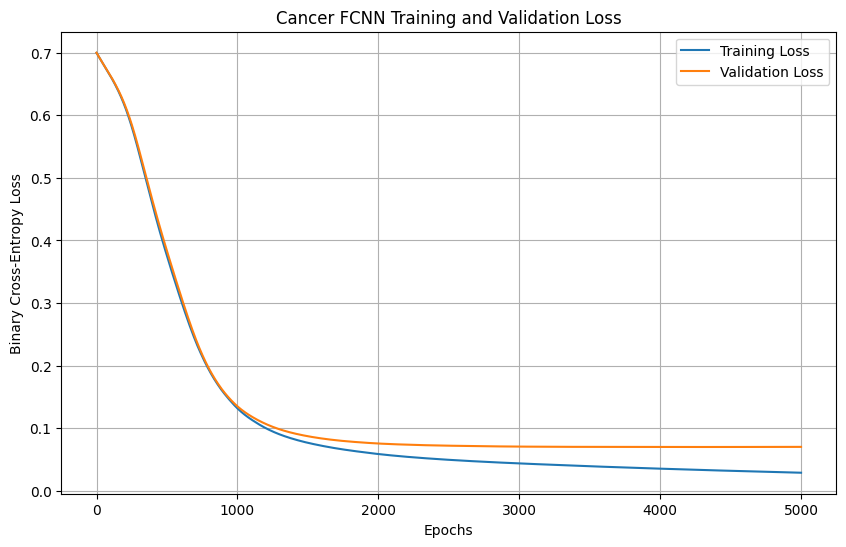

In [206]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(train_losses_Cancer, label='Training Loss')
plt.plot(val_losses_Cancer, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Binary Cross-Entropy Loss')
plt.title('Cancer FCNN Training and Validation Loss')

plt.legend()
plt.grid(True)
plt.show()

In [207]:
# Generate Cancer predictions using FCNN

model_Cancer.eval()

with torch.no_grad():
    Y_prob_Cancer = torch.sigmoid(model_Cancer(X_test_Cancer_t))

    # Convert probabilities to 0 or 1
    Y_pred_Cancer = (Y_prob_Cancer >= 0.5).int().numpy().flatten()

Accuracy, Precision, Recall,F1

In [208]:
#Let's evaluate the model using model evaluation metrics such as accuracy, precision, and recall.
from sklearn import metrics
print("Accuracy:",metrics.accuracy_score(Y_test_Cancer, Y_pred_Cancer))
print("Precision:",metrics.precision_score(Y_test_Cancer, Y_pred_Cancer))
print("Recall:",metrics.recall_score(Y_test_Cancer, Y_pred_Cancer))
print("F1 Score:", metrics.f1_score(Y_test_Cancer, Y_pred_Cancer))

Accuracy: 0.9736842105263158
Precision: 0.975609756097561
Recall: 0.9523809523809523
F1 Score: 0.963855421686747


**Confusion Matrix**

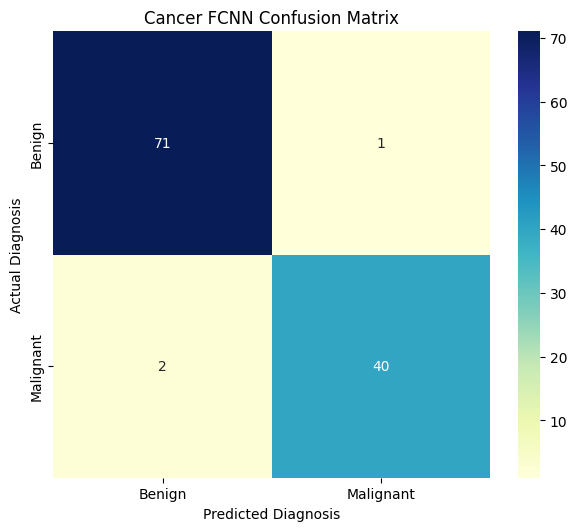

In [209]:
# Cancer FCNN Confusion Matrix

import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cnf_matrix_Cancer = confusion_matrix(
    Y_test_Cancer, Y_pred_Cancer
)

class_names_Cancer = ['Benign', 'Malignant']

fig, ax = plt.subplots(figsize=(6, 5))

# Create heatmap
sns.heatmap(
    pd.DataFrame(cnf_matrix_Cancer),
    annot=True,
    cmap="YlGnBu",
    fmt='g',
    xticklabels=class_names_Cancer,
    yticklabels=class_names_Cancer
)

plt.tight_layout()
plt.title('Cancer FCNN Confusion Matrix')
plt.ylabel('Actual Diagnosis')
plt.xlabel('Predicted Diagnosis')
plt.show()

**Problem 2b**

logistic Regression

In [210]:
# Logistic Regression Using SGD

from sklearn.linear_model import SGDClassifier

iterations = 100

classifier_Cancer_Penalty = SGDClassifier(
    loss="log_loss",
    learning_rate="constant",
    eta0=0.01,
    penalty="l2",
    alpha=0.001,
    random_state=0
)

for i in range(iterations):

    classifier_Cancer_Penalty.partial_fit(
        X_train_Cancer_scaled,
        Y_train_Cancer,
        classes=np.array([0, 1])
    )

# Test predictions
Y_pred_Logistic_Cancer = classifier_Cancer_Penalty.predict(
    X_test_Cancer_scaled
)

**SVM Training**

In [211]:
# SVM Training

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svc = SVC(kernel='rbf', class_weight='balanced')

param_grid = {
    'C': [1, 5, 10, 50],
    'gamma': [0.0001, 0.0005, 0.001, 0.005]
}

grid = GridSearchCV(
    svc,
    param_grid,
    cv=5
)

grid.fit(X_train_Cancer_scaled, Y_train_Cancer)

print("Best Parameters:", grid.best_params_)

# Test predictions
Y_pred_SVM_Cancer = grid.predict(X_test_Cancer_scaled)

Best Parameters: {'C': 50, 'gamma': 0.001}


In [212]:
# Problem 2b - Model Comparison

from sklearn import metrics

def evaluate_Cancer(Y_true, Y_pred):

    accuracy = metrics.accuracy_score(Y_true, Y_pred)
    precision = metrics.precision_score(Y_true, Y_pred)
    recall = metrics.recall_score(Y_true, Y_pred)
    f1 = metrics.f1_score(Y_true, Y_pred)

    return accuracy, precision, recall, f1


results_Cancer = pd.DataFrame(
    [
        evaluate_Cancer(Y_test_Cancer, Y_pred_Cancer),
        evaluate_Cancer(Y_test_Cancer, Y_pred_Logistic_Cancer),
        evaluate_Cancer(Y_test_Cancer, Y_pred_SVM_Cancer)
    ],
    columns=['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    index=['FCNN', 'Logistic Regression', 'SVM']
)

print(results_Cancer)

                     Accuracy  Precision    Recall  F1 Score
FCNN                 0.973684    0.97561  0.952381  0.963855
Logistic Regression  0.982456    0.97619  0.976190  0.976190
SVM                  0.982456    0.97619  0.976190  0.976190
